# WEEK 2 - PREPARING AND ANALYZING DATA

# Introduction
The purpose of this analysis is to understand patterns in learner engagement, identify popular opportunities, examine participation trends over time, and assess the quality and consistency of the available data. The analysis also explores relationships between selected numerical variables and investigates factors that may be associated with successful opportunity completion.

The findings will provide insights into learner participation and opportunity performance, helping inform future decisions about opportunity planning, learner engagement, and program improvement. For this analysis, **successful completion is defined as a record with the status “Rewards Award.”**

## Objectives

The main objectives of this notebook are to:

1. **Understand and refine the dataset**
2. **Conduct Exploratory Data Analysis (EDA)**
3. **Visualize Participation Trends**
4. **Interpret Insights**
   
## Scope and Approach

The analysis follows a structured workflow involving data inspection, data cleaning, feature engineering, descriptive statistics, and visual exploration. Where appropriate, derived variables such as signup month, signup hour, age groups, opportunity duration, and days until the opportunity deadline are used to support further analysis.

# Data Understanding and Cleaning

In [58]:
import pandas as pd
import numpy as np
import seaborn as sns
import sqlite3
import matplotlib.pyplot as plt
%matplotlib inline
plt.style.use('seaborn-v0_8-darkgrid')

In [24]:
df = pd.read_csv("clean_data.csv")
df.head()

,Learner SignUp DateTime,Opportunity Id,Opportunity Name,Opportunity Category,Opportunity End Date,First Name,Date of Birth,Gender,Country,Institution Name,Current/Intended Major,Entry created at,Status Description,Status Code,Apply Date,Opportunity Start Date,Age at SignUp,Apply Before SignUp,Possible Test Record
0,18/08/2023 22:34,00000000-0GNT-FT74-MZT8-93VC0G,Digital Marketing,Internship,11/03/2024 18:00,Sushanth Kumar Raju,23/04/2000,Male,United States,Saint Louis University,Information Systems,11/03/2024 12:01,Rejected,1030,21/08/2023 19:39,NaN,23,False,False
1,06/05/2023 10:59,00000000-0GNT-FT74-MZT8-93VC0G,Digital Marketing,Internship,11/03/2024 18:00,Avanaganti,25/04/2000,Male,United States,Saint Louis University,Information Systems,11/03/2024 12:01,Rejected,1030,18/01/2024 04:02,NaN,23,False,False
2,16/06/2023 09:20,00000000-0GNT-FT74-MZT8-93VC0G,Digital Marketing,Internship,11/03/2024 18:00,Fnu,19/04/2000,Male,United States,Saint Louis University,Information Systems,11/03/2024 12:01,Rejected,1030,25/01/2024 04:08,NaN,23,False,False
3,07/08/2023 15:59,00000000-0GNT-FT74-MZT8-93VC0G,Digital Marketing,Internship,11/03/2024 18:00,Rahul,28/04/2000,Male,United States,Saint Louis University,Information Systems,11/03/2024 12:01,Rejected,1030,19/02/2024 20:22,NaN,23,False,False
4,22/02/2024 16:29,00000000-0GNT-FT74-MZT8-93VC0G,Digital Marketing,Internship,11/03/2024 18:00,Varun Kumar,11/08/2000,Male,United States,Saint Louis University,Information Systems,11/03/2024 12:02,Rejected,1030,22/02/2024 16:45,NaN,23,False,False


In [16]:
df.shape

(8558, 19)

In [31]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8558 entries, 0 to 8557
Data columns (total 19 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   Learner SignUp DateTime  8558 non-null   datetime64[ns]
 1   Opportunity Id           8558 non-null   object        
 2   Opportunity Name         8558 non-null   object        
 3   Opportunity Category     8558 non-null   object        
 4   Opportunity End Date     8558 non-null   datetime64[ns]
 5   First Name               8558 non-null   object        
 6   Date of Birth            8558 non-null   datetime64[ns]
 7   Gender                   8558 non-null   object        
 8   Country                  8558 non-null   object        
 9   Institution Name         8558 non-null   object        
 10  Current/Intended Major   8558 non-null   object        
 11  Entry created at         8558 non-null   datetime64[ns]
 12  Status Description       8558 non-

In [18]:
df.duplicated().sum()

np.int64(0)

In [19]:
df["Country"].value_counts()

Country
United States         3976
India                 2836
Nigeria                760
Ghana                  275
Pakistan               219
                      ... 
Falkland Islands         1
Namibia                  1
Sri Lanka                1
Dominican Republic       1
Lesotho                  1
Name: count, Length: 70, dtype: int64

In [32]:
df["Opportunity Category"].value_counts()

Opportunity Category
Internship     5421
Course         2037
Event           545
Competition     425
Engagement      130
Name: count, dtype: int64

In [33]:
df["Opportunity Name"].value_counts()

Opportunity Name
Career Essentials: Getting Started with Your Professional Journey    1423
Data Visualization                                                    980
Project Management                                                    836
Health Care Management                                                784
Digital Marketing                                                     559
Data Visualization Associate                                          551
Business Consulting                                                   483
Project Management Associate                                          478
Innovation & Entrepreneurship                                         419
CPR/AED Certification                                                 389
Digital Strategy Virtual Internship                                   331
Startup Mastery Workshop                                              262
Freelance Mastery workshop                                            237
Jump Start: Developin

In [34]:
df["Opportunity Id"].value_counts()

Opportunity Id
00000000-0GN2-A0AY-7XK8-C5FZPP    1423
00000000-0GWQ-AXC5-X45C-2MHJ28     980
00000000-0GHB-4N83-QX9K-JM48K2     836
00000000-0GRA-BD28-CXVV-EYEX21     784
00000000-0GNT-FT74-MZT8-93VC0G     559
00000000-10GG-17ZM-AP4T-WQVBGQ     551
00000000-101B-RJY9-TVWC-6XG9BH     483
00000000-10SA-ZXDA-E05A-N2CGAN     478
00000000-0GZY-NNHV-FJWW-PTA9VX     419
00000000-10WC-BS50-CYGD-X97ES4     389
00000000-10CD-3CAK-3FZK-9VXKRM     331
00000000-10S6-HVRK-ZDAM-90C0F8     262
00000000-10GQ-RJHT-3G4S-BKGBY1     237
00000000-100J-PM3A-0WJ8-5T68M5     192
00000000-106T-FSAJ-KDBX-40ZGNV     138
00000000-10QW-PYTT-CJCX-7VQBTT     121
00000000-10A5-TYD2-181G-D2J679     116
00000000-10RQ-JXA9-NNKD-EW5RCF     112
00000000-101Y-HSX2-0DFJ-QCKQBR      55
00000000-104G-3FS6-3SV3-JKHVQB      46
00000000-10WW-X340-GTVH-RR52VF      33
00000000-10YM-B80K-RNNJ-YAVQ7V       9
00000000-0GHG-N3NG-584M-44MK40       4
Name: count, dtype: int64

In [20]:
df["Gender"].value_counts()

Gender
Male                     5018
Female                   3522
Don't want to specify      15
Other                       3
Name: count, dtype: int64

In [21]:
df["Status Description"].value_counts()

Status Description
Rejected          3569
Team Allocated    3276
Started            767
Dropped Out        617
Waitlisted         109
Applied            105
Withdraw            86
Rewards Award       29
Name: count, dtype: int64

In [35]:
df["Institution Name"].value_counts()

Institution Name
Saint Louis University                                    4504
Illinois Institute of Technology                           157
Webster University                                          72
SRM Institute of Science and Technology                     60
Vignan's Foundation for Science, Technology & Research      58
                                                          ... 
Acropolis Institute of Technology and Research               1
Gurukul kangri deemed to be university                       1
Gurukul kangri Vishwavidyalaya                               1
Institute of Charted Accountance of India                    1
Sies                                                         1
Name: count, Length: 1666, dtype: int64

In [37]:
df["Apply Before SignUp"].value_counts()

Apply Before SignUp
False    8455
True      103
Name: count, dtype: int64

In [38]:
df["Possible Test Record"].value_counts()

Possible Test Record
False    8542
True       16
Name: count, dtype: int64

In [22]:
df.isnull().sum()

Learner SignUp DateTime       0
Opportunity Id                0
Opportunity Name              0
Opportunity Category          0
Opportunity End Date          0
First Name                    0
Date of Birth                 0
Gender                        0
Country                       0
Institution Name              0
Current/Intended Major        0
Entry created at              0
Status Description            0
Status Code                   0
Apply Date                    0
Opportunity Start Date     3794
Age at SignUp                 0
Apply Before SignUp           0
Possible Test Record          0
dtype: int64

In [30]:
# convert datetime columnc into ns[64] datetime format
date_columns = [
    "Learner SignUp DateTime",
    "Opportunity End Date",
    "Date of Birth",
    "Entry created at",
    "Apply Date",
    "Opportunity Start Date"
]

for col in date_columns:
    df[col] = pd.to_datetime(df[col], format="mixed")

In [54]:
df_clean = df.copy()
df_analysis = df.copy()

In [94]:
df_analysis = df_analysis.copy()

# Signup date/time features
signup_col = "Learner SignUp DateTime"

if signup_col in df_analysis.columns:
    df_analysis["Signup Date"] = df_analysis[signup_col].dt.date
    df_analysis["Signup Year"] = df_analysis[signup_col].dt.year
    df_analysis["Signup Month"] = df_analysis[signup_col].dt.month
    df_analysis["Signup Quarter"] = df_analysis[signup_col].dt.quarter
    df_analysis["Signup Day of Week"] = df_analysis[signup_col].dt.day_name()
    df_analysis["Signup Hour"] = df_analysis[signup_col].dt.hour

# Days between signup and opportunity end
df_analysis["Days Until Opportunity End"] = (
    df_analysis["Opportunity End Date"].dt.normalize()
    - df_analysis[signup_col].dt.normalize()
).dt.days

df_analysis["Opportunity Duration Days"] = (
    df_analysis["Opportunity End Date"]
    - df_analysis["Opportunity Start Date"]
).dt.days

# Application lead time
df_analysis["Apply Lead Time Days"] = (
    df_analysis[signup_col].dt.normalize()
    - df_analysis["Apply Date"].dt.normalize()
).dt.days

# Learner age bands
df_analysis["Age Group"] = pd.cut(
    df_analysis["Age at SignUp"],
    bins=[-np.inf, 17, 24, 34, 44, 54, 100, np.inf],
    labels=[
        "17 and under", "18-24", "25-34", "35-44",
        "45-54", "55-100", "Over 100"
    ]
)

# Opportunity category cleanup
df_analysis["Opportunity Category"] = (
    df_analysis["Opportunity Category"]
    .astype("string")
    .str.strip()
)

# Check newly created features
new_features = [
    "Signup Year",
    "Signup Month",
    "Signup Day of Week"
    "Signup Hour"
    "Days Until Opportunity End",
    "Apply Lead Time Days",
    "Age Group"
]

display(
    df_analysis[
        [c for c in new_features if c in df_analysis.columns]
    ].head()
)

print("Feature engineering completed.")

,Signup Year,Signup Month,Apply Lead Time Days,Age Group
0,2023,8,-3,18-24
1,2023,6,-227,18-24
2,2023,6,-223,18-24
3,2023,7,-226,18-24
4,2024,2,0,18-24


Feature engineering completed.


In [95]:
df_analysis.head()

,Learner SignUp DateTime,Opportunity Id,Opportunity Name,Opportunity Category,Opportunity End Date,First Name,Date of Birth,Gender,Country,Institution Name,...,Signup Date,Signup Year,Signup Month,Signup Quarter,Days Until Opportunity End,Apply Lead Time Days,Age Group,Signup Day of Week,Signup Hour,Opportunity Duration Days
0,2023-08-18 22:34:00,00000000-0GNT-FT74-MZT8-93VC0G,Digital Marketing,Internship,2024-11-03 18:00:00,Sushanth Kumar Raju,2000-04-23,Male,United States,Saint Louis University,...,2023-08-18,2023,8,3,443,-3,18-24,Friday,22,NaN
1,2023-06-05 10:59:00,00000000-0GNT-FT74-MZT8-93VC0G,Digital Marketing,Internship,2024-11-03 18:00:00,Avanaganti,2000-04-25,Male,United States,Saint Louis University,...,2023-06-05,2023,6,2,517,-227,18-24,Monday,10,NaN
2,2023-06-16 09:20:00,00000000-0GNT-FT74-MZT8-93VC0G,Digital Marketing,Internship,2024-11-03 18:00:00,Fnu,2000-04-19,Male,United States,Saint Louis University,...,2023-06-16,2023,6,2,506,-223,18-24,Friday,9,NaN
3,2023-07-08 15:59:00,00000000-0GNT-FT74-MZT8-93VC0G,Digital Marketing,Internship,2024-11-03 18:00:00,Rahul,2000-04-28,Male,United States,Saint Louis University,...,2023-07-08,2023,7,3,484,-226,18-24,Saturday,15,NaN
4,2024-02-22 16:29:00,00000000-0GNT-FT74-MZT8-93VC0G,Digital Marketing,Internship,2024-11-03 18:00:00,Varun Kumar,2000-11-08,Male,United States,Saint Louis University,...,2024-02-22,2024,2,1,255,0,18-24,Thursday,16,NaN


**Data Cleaning**

Data cleaning involved checking data types, handling date fields, examining missing values and duplicate records, and validating categorical and numerical variables. Date-related checks identified 527 invalid opportunity durations, 205 signups occurring after opportunity end dates, and 103 records flagged as applications occurring before signup. These records were identified for further investigation to improve data reliability. The dataset was also reviewed for inconsistencies and potential anomalies before feature engineering and predictive modeling.

# Explatory Data Analysis

### 1. Signup distribution by opportunity category

  Opportunity Category  Signup Count
0           Internship          5421
1               Course          2037
2                Event           545
3          Competition           425
4           Engagement           130


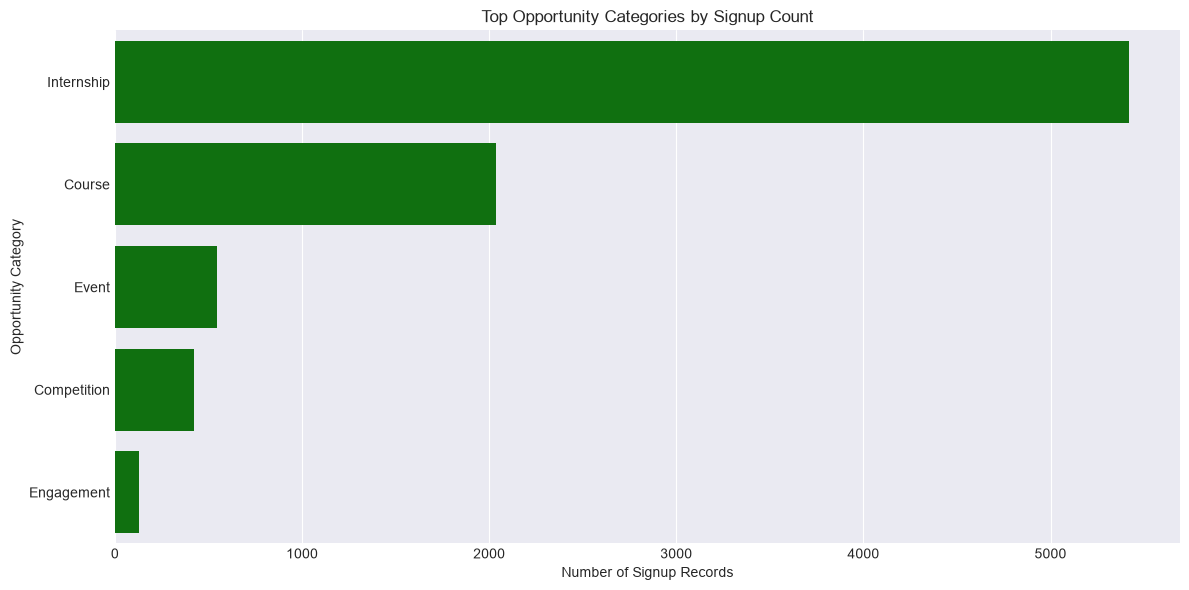

In [67]:
category_counts = (
    df_analysis["Opportunity Category"]
    .value_counts()
    .rename_axis("Opportunity Category")
    .reset_index(name="Signup Count")
)

print(category_counts)

plt.figure(figsize=(12, 6))
sns.barplot(
    x=category_counts["Signup Count"],
    y=category_counts["Opportunity Category"],
    color="green"
)
plt.title("Top Opportunity Categories by Signup Count")
plt.xlabel("Number of Signup Records")
plt.ylabel("Opportunity Category")
plt.tight_layout()
plt.show();

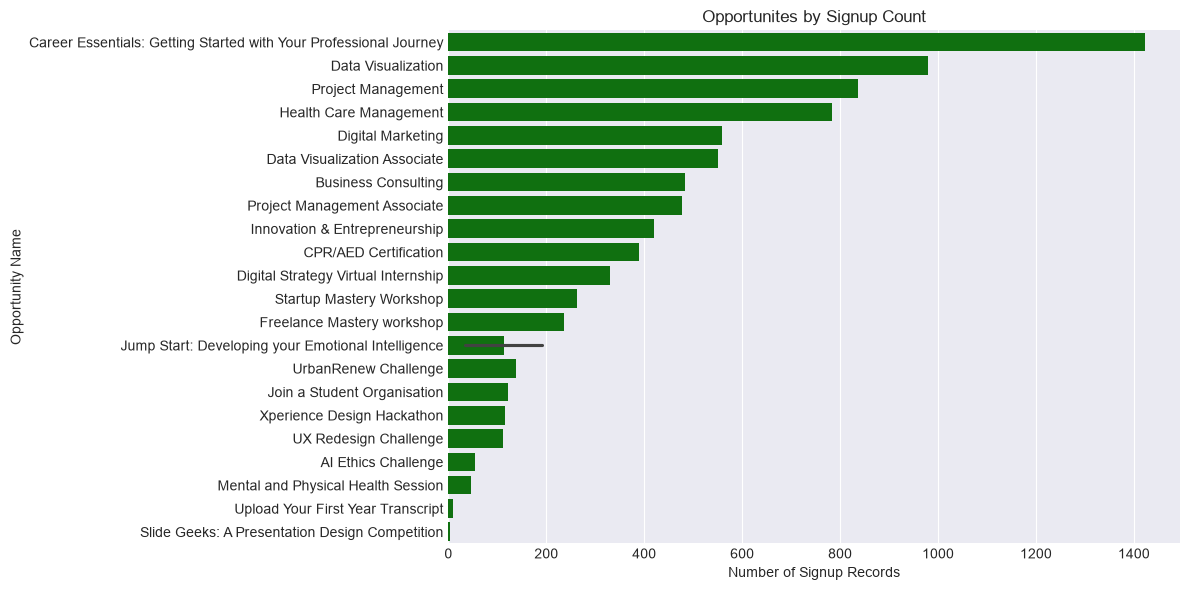

In [111]:
opportunity_summary = (
    df_analysis.groupby(
        ["Opportunity Id", "Opportunity Name"], dropna=False
    )
    .size()
    .reset_index(name="Signup Count")
    .sort_values("Signup Count", ascending=False)
)

plt.figure(figsize=(12, 6))
sns.barplot(
    x=opportunity_summary["Signup Count"],
    y=opportunity_summary["Opportunity Name"],
    color="green"
)
plt.title("Opportunites by Signup Count")
plt.xlabel("Number of Signup Records")
plt.ylabel("Opportunity Name")
plt.tight_layout()
plt.show();

***Insight:***
> Getting Started with Your Path has the highest reported signup count, at 1,423.
> That is approximately 16.6% of all records.Data Visualization ranks second with 980 signups, followed by Project Management with 836.

> Health Care Management also attracts substantial interest, with 784 signups.Career-focused, professional-development, and practical-skills opportunities appear prominently among the most popular offerings.

> The two Data Visualization opportunities collectively account for 1,531 signup records, while the two Project Management opportunities account for 1,314. This suggests sustained interest in these subject areas, although it does not establish that the same learners participated in both.

### 2. Signup Trends Overtime

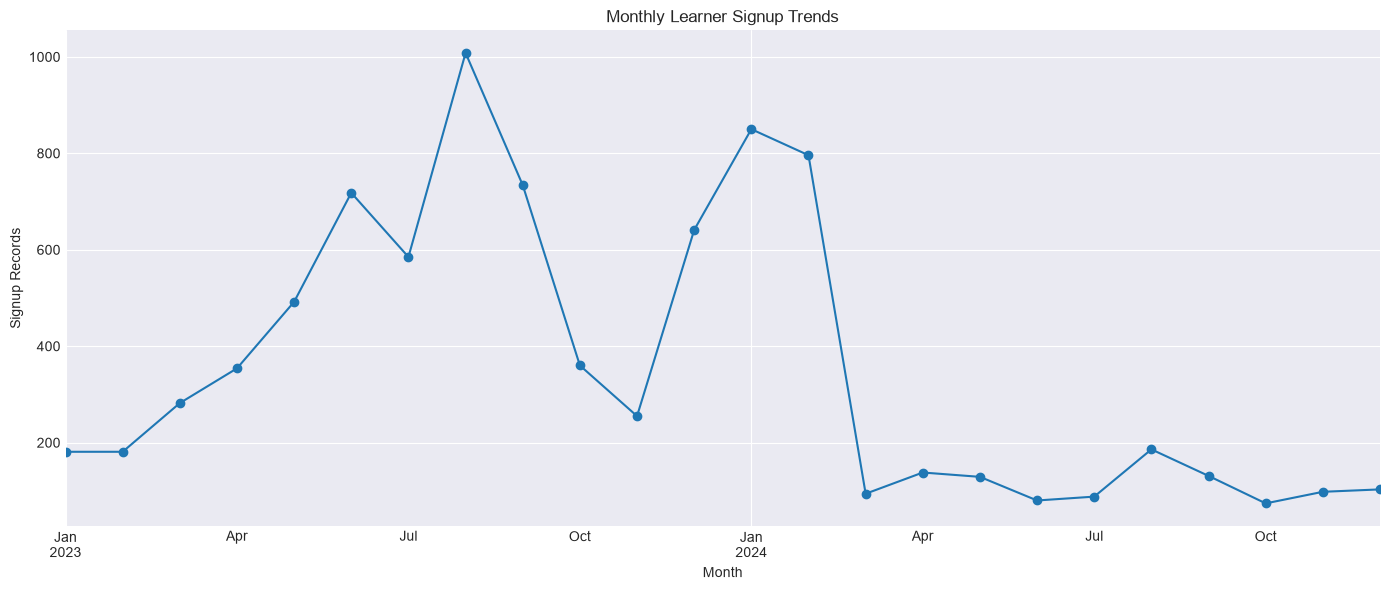

In [73]:
valid_signups = df_analysis.dropna(subset=[signup_col]).copy()

monthly_signups = (
    valid_signups.set_index(signup_col)
    .resample("MS")
    .size()
    .rename("Signup Count")
)

plt.figure(figsize=(14, 6))
monthly_signups.plot(marker="o")
plt.title("Monthly Learner Signup Trends")
plt.xlabel("Month")
plt.ylabel("Signup Records")
plt.tight_layout()
plt.show();

***Insight:***
> August 2023 was the peak month, with 1,008 signup records.

> Signup volumes increased from 181 in January 2023 to 1,008 in August, indicating a substantial rise in recorded interest during the first eight months.Signup counts remained relatively low for the rest of 2024, with a smaller rebound in August to 186.

> The sharp decline beginning in March 2024 is one of the most important findings in this dataset. Possible explanations include changes in opportunity availability, recruitment campaigns, platform activity, data collection, or reporting coverage.

### 3. Engagment Intensity

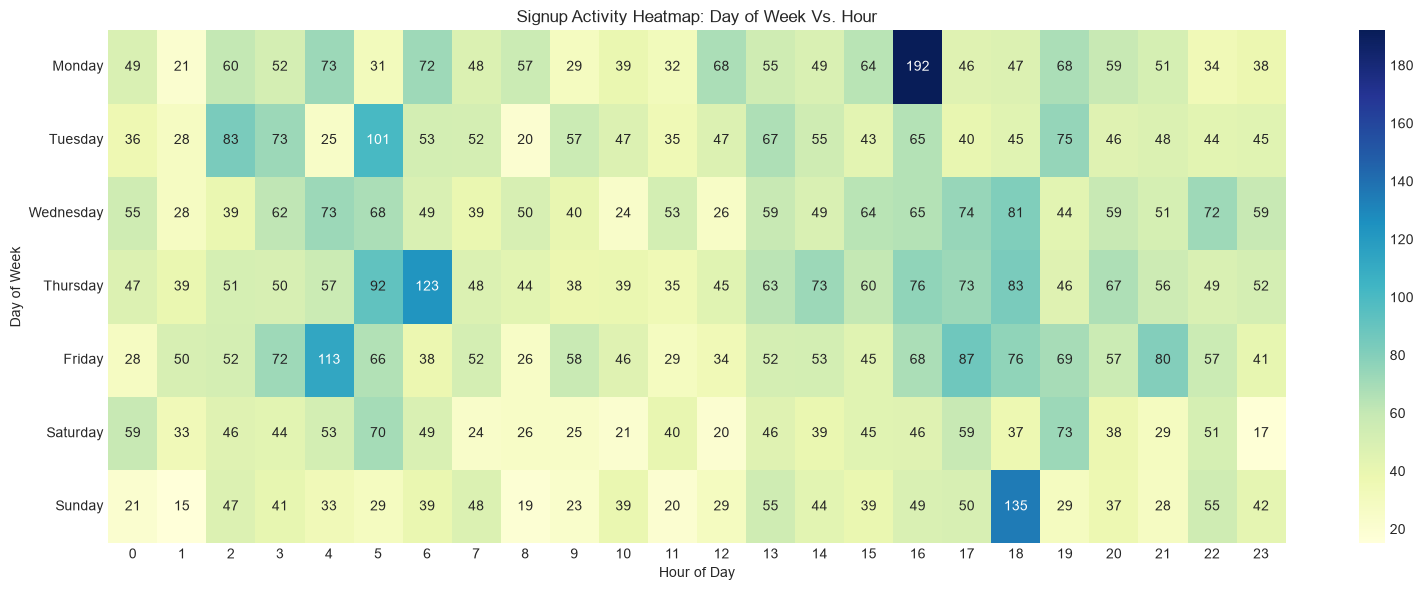

In [79]:
heatmap_data = df_analysis.pivot_table(
    index="Signup Day of Week",
    columns="Signup Hour",
    values="Opportunity Id",
    aggfunc="count",
    fill_value=0
    )

day_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

heatmap_data = heatmap_data.reindex(day_order).reindex(
    columns=range(24), fill_value=0
)

plt.figure(figsize=(16, 6))
sns.heatmap(
    heatmap_data,
    cmap="YlGnBu",
    annot=True,
    fmt=".0f"
)
plt.title("Signup Activity Heatmap: Day of Week Vs. Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Day of Week")
plt.tight_layout()
plt.show();

***Insight:***
> Signup activity occurs across weekdays, weekends, and different hours. The visible peaks suggest that learner activity is not confined to conventional working hours.

### 4. Student Demographics and Institution

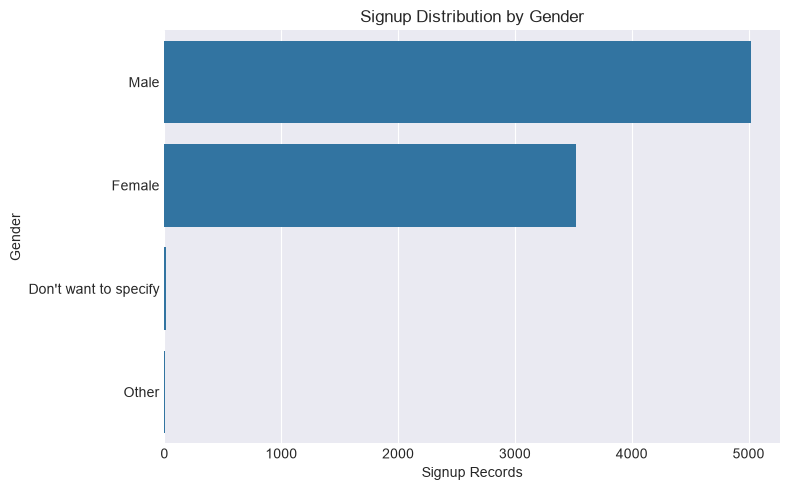

In [103]:
# Gender distribution
fig, ax = plt.subplots(figsize=(8,5))
gender_counts = df_analysis["Gender"].value_counts()

sns.barplot(x=gender_counts.values, y=gender_counts.index)
plt.title("Signup Distribution by Gender")
plt.xlabel("Signup Records")
plt.ylabel("Gender")
plt.tight_layout()
plt.show();

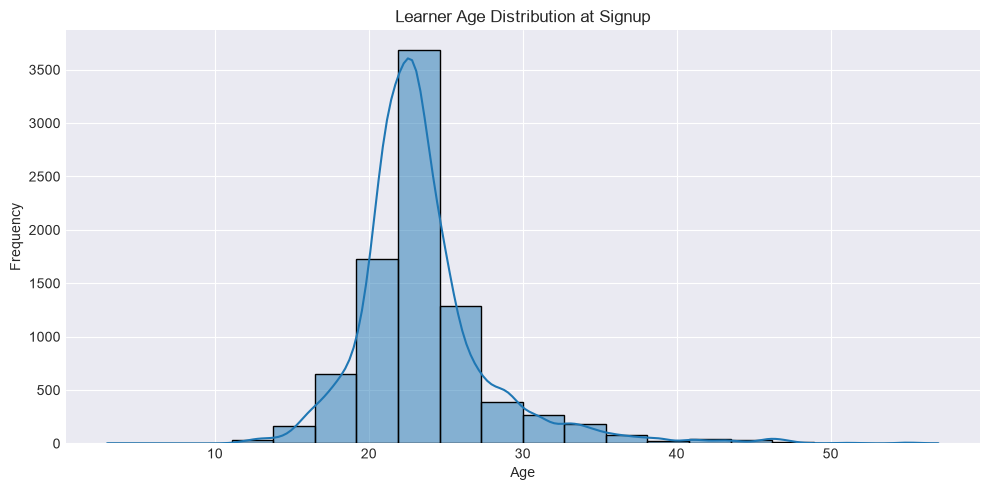

In [102]:
# Age distribution
age_data = df_analysis["Age at SignUp"].dropna()
age_data = age_data[age_data.between(0, 100)]

plt.figure(figsize=(10,5))
sns.histplot(age_data, bins=20, kde=True)
plt.title("Learner Age Distribution at Signup")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show();

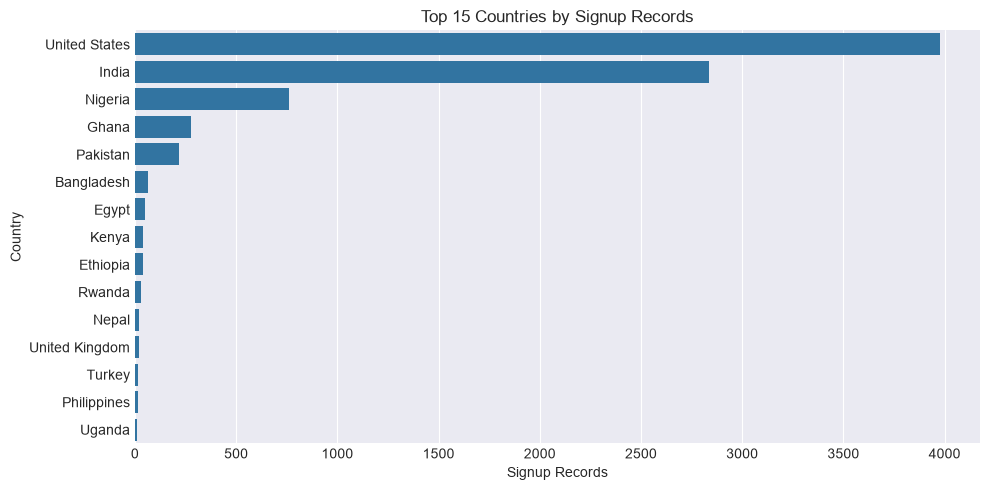

In [101]:
# Top countries
country_counts = df_analysis["Country"].value_counts().head(15)
plt.figure(figsize=(10,5))
sns.barplot(x=country_counts.values, y=country_counts.index)
plt.title("Top 15 Countries by Signup Records")
plt.xlabel("Signup Records")
plt.ylabel("Country")
plt.tight_layout()
plt.show();

***Insight:***
> The United States and India account for approximately 79.6% of all 8,558 signup records. Nigeria is a distant third.

> This suggests that recorded participation is geographically concentrated. However, these figures describe signup records, not necessarily unique learners, and do not establish why participation differs between countries.

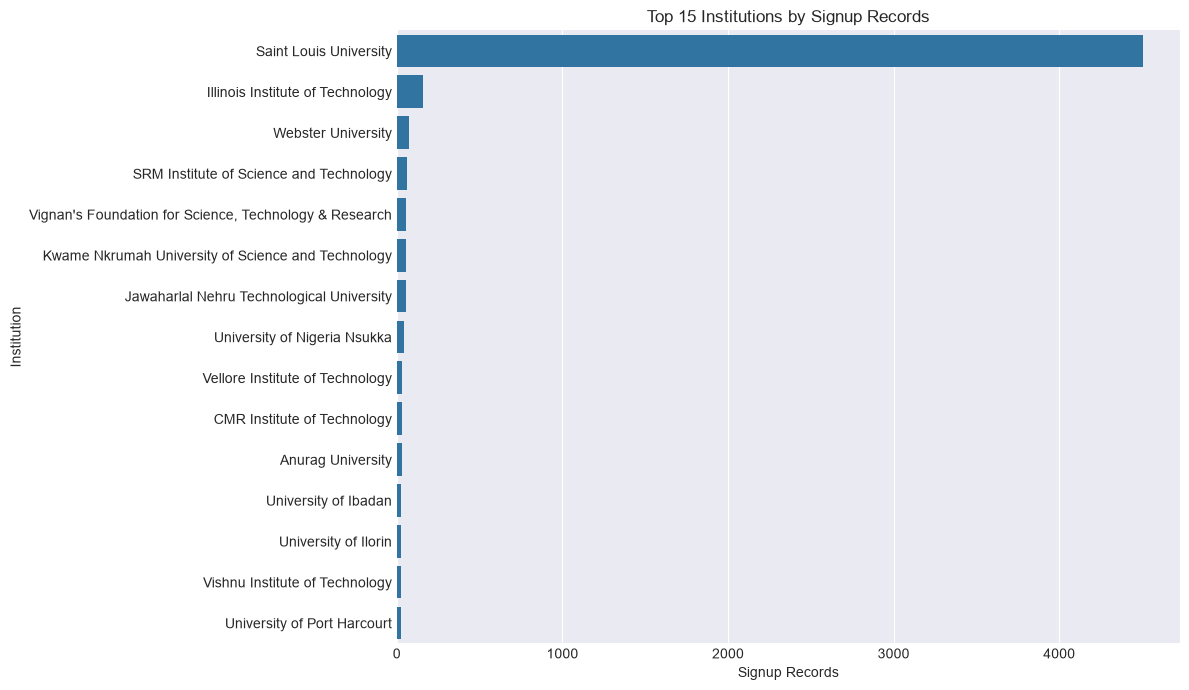

In [100]:
# Top institutions
institution_counts = (
    df_analysis["Institution Name"]
    .value_counts()
    .head(15)
)

plt.figure(figsize=(12, 7))
sns.barplot(
    x=institution_counts.values,
    y=institution_counts.index
)
plt.title("Top 15 Institutions by Signup Records")
plt.xlabel("Signup Records")
plt.ylabel("Institution")
plt.tight_layout()
plt.show();

***Insight:***
>Saint Louis University accounts for more than half of all signup records. This is a particularly important finding because it may strongly influence overall trends and model results.

>Before interpreting it as a genuine difference in learner interest, investigate whether the dataset covers a specific institutional partnership, whether the records represent unique learners, and whether missing institution names are substantial.

### 5. Application and Opportunity Timing Analysis

Signups after opportunity end: 205
Signups on opportunity end date: 8


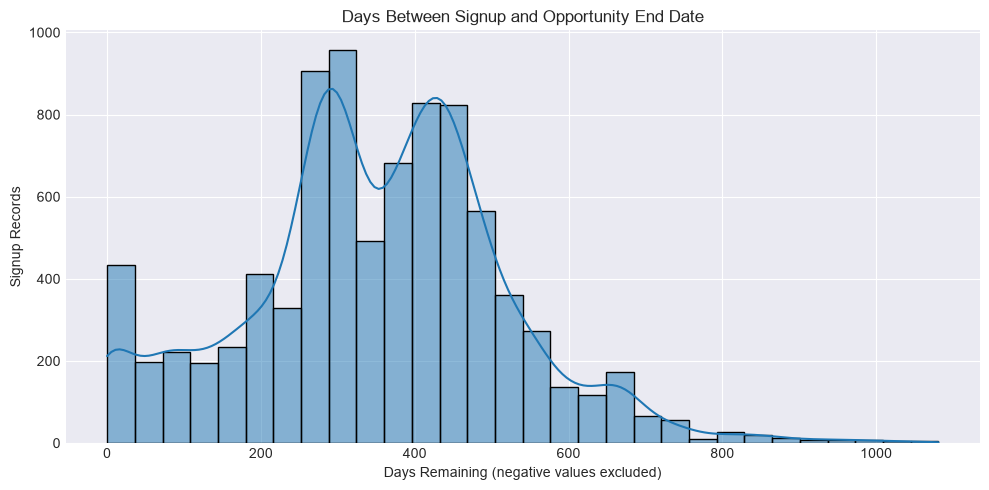

In [99]:
# Days remaining before opportunity deadline
deadline_data = df_analysis["Days Until Opportunity End"].dropna()

print("Signups after opportunity end:",
      (deadline_data < 0).sum())

print("Signups on opportunity end date:",
        (deadline_data == 0).sum())

plt.figure(figsize=(10, 5))
sns.histplot(
    deadline_data.clip(lower=0),
    bins=30,
    kde=True
)
plt.title("Days Between Signup and Opportunity End Date")
plt.xlabel("Days Remaining (negative values excluded)")
plt.ylabel("Signup Records")
plt.tight_layout()
plt.show();

***Insight:***
>The 205 post-deadline signups represent approximately 2.4% of the dataset.

>Possible explanations include late registrations, opportunities with extended deadlines, incorrect date fields, or differences in timezone handling. These records should be checked before deciding whether they are invalid.

>A useful validation table would include the opportunity name, signup timestamp, opportunity start and end dates, and the difference in days between signup and end date.

Invalid opportunity durations: 527


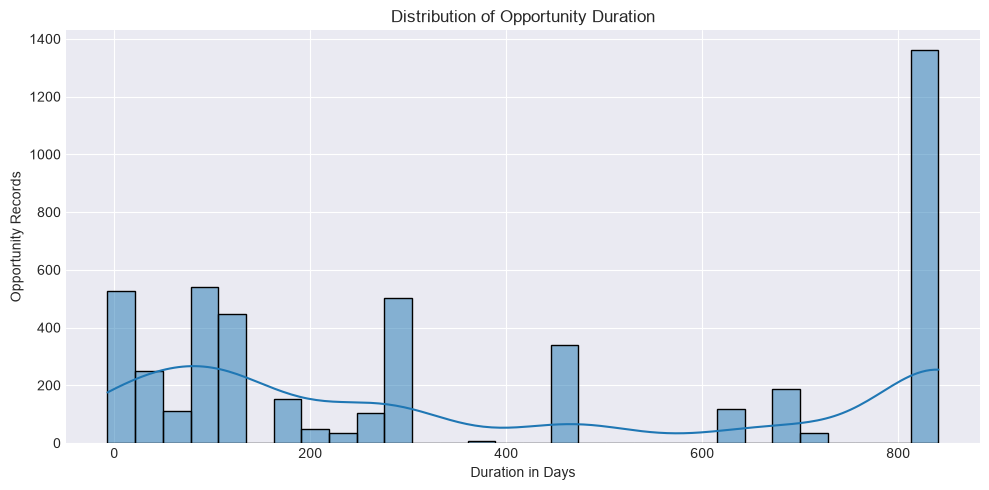

In [98]:
# Opportunity duration
duration_data = df_analysis["Opportunity Duration Days"].dropna()

print("Invalid opportunity durations:",
        (duration_data < 0).sum())

plt.figure(figsize=(10, 5))
sns.histplot(duration_data, bins=30, kde=True)
plt.title("Distribution of Opportunity Duration")
plt.xlabel("Duration in Days")
plt.ylabel("Opportunity Records")
plt.tight_layout()
plt.show();

***Insight:***
>527 invalid opportunity durations were identified. Check for missing dates, end dates before start dates, and unrealistic date values before interpreting the distribution.

>A large peak near approximately 820 days may represent genuinely long-running opportunities, a default end date, or a date-quality issue.
>The distribution is not smooth or normally distributed; several clusters suggest different opportunity types or date-setting practices.

Application timing flag:


,Signup Records
Apply Before SignUp,
False,8455
True,103


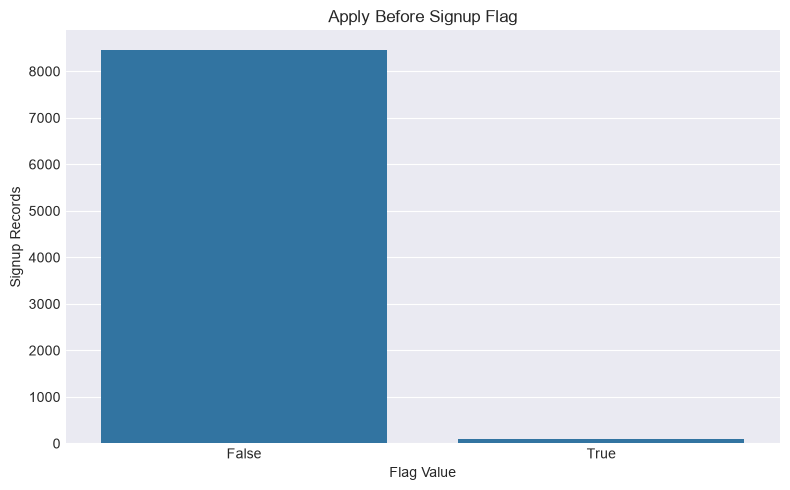

In [97]:
# Applications before versus after signup
apply_counts = df_analysis["Apply Before SignUp"].value_counts(
    dropna=False
)

print("Application timing flag:")
display(apply_counts.to_frame("Signup Records"))

plt.figure(figsize=(8, 5))
sns.barplot(
    x=apply_counts.index.astype(str),
    y=apply_counts.values
)
plt.title("Apply Before Signup Flag")
plt.xlabel("Flag Value")
plt.ylabel("Signup Records")
plt.tight_layout()
plt.show();

***Insight:***
>Almost all records have Apply Before SignUp = False. The 103 True records need investigation.

>If an application is expected to happen after signup, these records may indicate a date-ordering issue, mismatched records, or a problem in how the flag was calculated. Confirm the intended meaning of the flag before treating them as anomalies.

### 6. Correlation Analysis

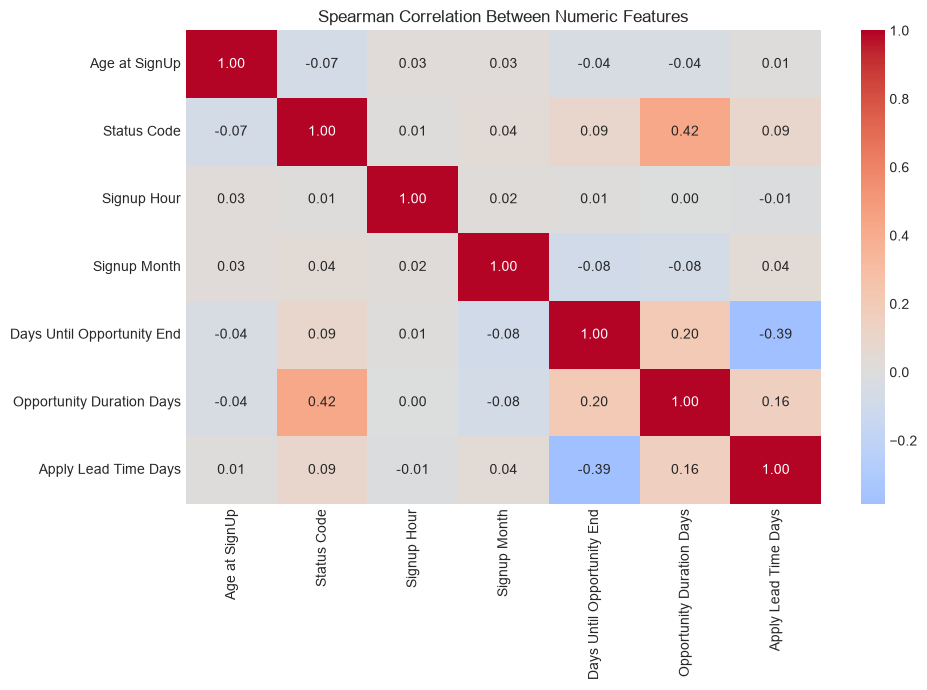

,Age at SignUp,Status Code,Signup Hour,Signup Month,Days Until Opportunity End,Opportunity Duration Days,Apply Lead Time Days
Age at SignUp,1.000000,-0.074315,0.025349,0.026960,-0.044377,-0.044319,0.012456
Status Code,-0.074315,1.000000,0.011983,0.041912,0.092267,0.423297,0.086742
Signup Hour,0.025349,0.011983,1.000000,0.016588,0.011304,0.001294,-0.008987
Signup Month,0.026960,0.041912,0.016588,1.000000,-0.083734,-0.076909,0.044554
Days Until Opportunity End,-0.044377,0.092267,0.011304,-0.083734,1.000000,0.204259,-0.386362
Opportunity Duration Days,-0.044319,0.423297,0.001294,-0.076909,0.204259,1.000000,0.162381
Apply Lead Time Days,0.012456,0.086742,-0.008987,0.044554,-0.386362,0.162381,1.000000


In [105]:
correlation_features = [
    "Age at SignUp",
    "Status Code",
    "Signup Hour",
    "Signup Month",
    "Days Until Opportunity End",
    "Opportunity Duration Days",
    "Apply Lead Time Days"
]

correlation_features = [
    c for c in correlation_features
    if c in df_analysis.columns
]

correlation_data = df_analysis[correlation_features].copy()

if len(correlation_features) >= 2:
    corr_matrix = correlation_data.corr(
        method="spearman",
        numeric_only=True
    )

    plt.figure(figsize=(10, 7))
    sns.heatmap(
        corr_matrix,
        annot=True,
        cmap="coolwarm",
        center=0,
        fmt=".2f"
    )
    plt.title("Spearman Correlation Between Numeric Features")
    plt.tight_layout()
    plt.show();

    display(corr_matrix)

***Insight:***
>The negative correlation of -0.386 is intuitive if longer time remaining before the deadline tends to correspond to a shorter interval between application and signup, depending on how Apply Lead Time Days is defined.

>The correlation of 0.423 between Status Code and Opportunity Duration Days needs more care. Status codes are often categorical identifiers, so a numerical correlation may not have a meaningful interpretation unless the codes represent an ordered scale. Examine status outcomes by duration instead.

>Also, correlation does not establish causation, and these correlations only describe linear relationships.

In [110]:
# Inspect all status values first
if "Status Description" in df_analysis.columns:
    print(
        df_analysis["Status Description"]
        .value_counts(dropna=False)
        .to_string()
    )

# Example ONLY: replace these values with verified successful statuses.
SUCCESS_STATUSES = ["Rewards Award"]

if SUCCESS_STATUSES and "Status Description" in df_analysis.columns:
    df_model = df_analysis.copy()

    status_normalized = (
        df_model["Status Description"]
        .astype("string").str.strip().str.casefold()
    )

    success_normalized = [
        s.strip().casefold() for s in SUCCESS_STATUSES
    ]

    df_model["Successful Participation"] = (
        status_normalized.isin(success_normalized).astype(int)
    )

    print("Outcome distribution:")
    display(
        df_model["Successful Participation"]
        .value_counts()
        .rename(index={0: "Other status", 1: "Successful"})
        .to_frame("Records")
    )

else:
    print(
        "Predictive modelling skipped. Define SUCCESS_STATUSES "
        "using verified outcome meanings first."
    )

Status Description
Rejected          3569
Team Allocated    3276
Started            767
Dropped Out        617
Waitlisted         109
Applied            105
Withdraw            86
Rewards Award       29
Outcome distribution:


,Records
Successful Participation,
Other status,8529
Successful,29


## Preparation for Modeling

The dataset provides a foundation for predictive modeling in Week 3. Potentially useful features include:
- Learner age
- Country
- Institution
- Opportunity category
- Signup timing
- Opportunity duration

However, data-quality issues and date inconsistencies must be addressed before training. Since only 29 of the 8,558 records represent successful completions (`Rewards Award`), class imbalance is a major challenge. The modeling stage will prioritize data cleaning, feature selection, prevention of data leakage, and appropriate evaluation metrics such as precision, recall, and F1-score.